## __Conditional Workflow Execution using Quadratic Equation__

In [15]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [2]:
class QuadState(TypedDict):
    ## Co efficients
    a: int
    b: int
    c: int

    ## equation and descriminant
    equation: str
    descrimination: float
    result: str

In [4]:
## Show equation function shows the equation in format ax2+bx+c
def show_equation(state: QuadState) -> QuadState:
    ## Retrieve the values
    equation = f"{state["a"]}x2 + {state["b"]}x + {state["c"]}"

    return {"equation": equation}

In [5]:
## Calculating Descriminant to find the root's feeling
def calculate_descriminant(state: QuadState) -> QuadState:
    ## Calculate the value
    descriminant = (state["b"] ** 2  -  (4 * state["a"] * state["c"]))

    return {"descrimination": descriminant}

In [12]:
### Real root
def real_roots(state: QuadState) -> QuadState:
    ## -b + Sqrt(d) / 2a

    root1 = (-state["b"] + state["descrimination"] ** 0.5) /  (2 * state["a"])
    root2 = (-state["b"] - state["descrimination"] ** 0.5) /  (2 * state["a"])

    result = f"The roots are {root1} and {root2}"

    return {"result": result}

In [13]:
## Reprated roots
def repeated_node(state: QuadState) -> QuadState:
    ## -b / 2a

    root = (-state["b"] / (2 * state["a"]))

    result = f"Only repeating root is {root}"

    return {"result": result}

In [14]:
## No real roots
def no_real_root(state: QuadState) -> QuadState:
    ## No real roots

    result = f"No real roots exist"

    return {"result": result}

In [16]:
## Check condition
def check_condition(state: QuadState) -> Literal["real_roots", "repeated_node", "no_real_root"]:
    ## Telling condition
    if state["descrimination"] > 0:
        return "real_roots"

    elif state["descrimination"] == 0:
        return "repeated_node"

    else:
        return "no_real_root"

In [20]:
## Building Langgraph
graph = StateGraph(QuadState)


## Add sequential state
graph.add_node("show_equation", show_equation)
graph.add_node("calculate_descriminant", calculate_descriminant)


## Add Conditional state
graph.add_node("real_roots", real_roots)
graph.add_node("repeated_node", repeated_node)
graph.add_node("no_real_root", no_real_root)

## Add sequential edges
graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_descriminant")


## Add conditional Edges
graph.add_conditional_edges("calculate_descriminant", check_condition)
graph.add_edge("real_roots", END)
graph.add_edge("repeated_node", END)
graph.add_edge("no_real_root", END)


## Compiling the graph
workflow = graph.compile()


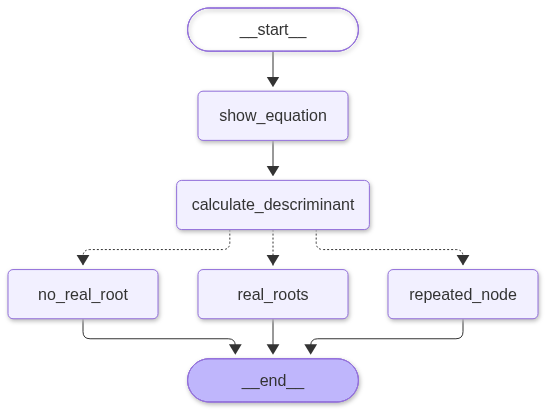

In [21]:
workflow

In [22]:
initial_state = {
    "a": 4, 
    "b": -5,
    "c": -4
}

result = workflow.invoke(initial_state)

In [23]:
print(result)

{'a': 4, 'b': -5, 'c': -4, 'equation': '4x2 + -5x + -4', 'descrimination': 89, 'result': 'The roots are 1.8042476415070754 and -0.5542476415070754'}
